# Class 10: Link Prediction

Goal of today's class:
1. Define canonical link prediction tasks
2. Introduce basic measures for link prediction
3. Discuss techniques for evaluating link prediction algorithms

*Content Acknowledgements: Parts of this lesson draw from material by Matteo Chinazzi and Qian Zhang. Much of it is adapted from the 2024 final project of [Yixuan Liu](https://github.com/liu-yi-xuan), a PhD student in Network Science at Northeastern University!*
__________

## Getting today's notebook

**Every class, duplicate the notebook before you run anything, and work in the copy.** Running a cell changes the file, and a changed original can block your next pull.

1. Log in to [Open OnDemand](https://ood.explorer.northeastern.edu/), open the **Courses** menu, and click **JupyterLab (Python)**. Launch it with the same settings as last class; they should already be filled in.
2. Once JupyterLab starts, open a terminal (**File → New → Terminal**) and pull the new material, where `USERNAME` is your Northeastern username:
   ```bash
   cd /courses/NETS7052.202710/students/USERNAME/nets7052_fa26
   git fetch upstream
   git checkout main
   git merge --no-edit upstream/main
   ```
   Once you've committed work of your own to your fork (Assignment 1, for example), this merge needs a commit message. `--no-edit` lets Git write that message itself instead of opening a text editor in your terminal.
3. **Duplicate today's notebook before you run anything.** In the file browser, open `notebooks/class_10_link_prediction/`, right-click `class_10_link_prediction.ipynb`, and choose **Duplicate**. Open the copy (`class_10_link_prediction-Copy1.ipynb`) and work there.
4. Check that the top-right corner of the notebook says **Python (cmns-core)**. If it doesn't, choose **Kernel → Change Kernel…** and pick it.

**If the merge doesn't work:**

- *"Your local changes to the following files would be overwritten by merge"*: you changed a notebook that I've since updated, and Git lists which one. If you took notes in it, duplicate it first. Then close it and reset it, using the path Git listed:
  ```bash
  git restore notebooks/class_06_data_science/class_06_data_science.ipynb
  ```

  `git restore` throws away every change you made to that one file and puts back the version from your last pull. Git can't undo it, which is why you duplicate first. Then run `git merge --no-edit upstream/main` again.
- *"'upstream' does not appear to be a git repository"*: you missed a step in Class 0. Run this, then start again from `git fetch upstream`:
  ```bash
  git remote add upstream https://github.com/computational-methods-network-science/nets7052_fa26.git
  ```
- **Git asks for a GitHub username or password:** don't type them. Your `upstream` address is wrong. Run this, then start again from `git fetch upstream`:
  ```bash
  git remote set-url upstream https://github.com/computational-methods-network-science/nets7052_fa26.git
  ```

In [1]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rc

# White backgrounds for axes, figures and saved files; gridlines drawn behind the data
rc('axes', axisbelow=True, fc='w')
rc('figure', fc='w')
rc('savefig', fc='w')

## Introduction to link prediction in networks

In many real-world systems, networks are not static: new ties appear over time (friendships, collaborations, hyperlinks, trade relations), and sometimes ties disappear. Sometimes, the network was collected with errors present, or there is inherent stochasticity or noise in the link formation process. Our basic predictive task, then, is:

> Given a snapshot of a network at time $t$, which pairs of nodes are currently not connected but either likely will be at time $t + \Delta t$ or *should already be but are not through network noise*?

This formulation covers two closely related problems (Liben-Nowell and Kleinberg, 2007; Lü and Zhou, 2011):

* **Future link prediction**, where we treat the current graph as $G(t)$ and try to anticipate edges that will appear at a later time $t + \Delta t$ but are not yet present.
* **Missing link inference**, where we treat the observed network as a noisy or incomplete version of some latent "true" graph and try to infer edges that should exist but were not observed.

In both cases, the core task is to assign a score $s(i,j)$ to each *non-edge* $(i,j)$ and to rank these candidate pairs by how likely they are to be "real" edges under whatever mechanism we believe is shaping the network.

![](images/link_prediction.png)

### A wide range of application areas

* recommendation systems, where we represent users and items as a bipartite graph and predict which missing user-item edges are most likely to appear in the future;
* social and information networks, where we forecast new friendships, citations, or hyperlinks based on the current topology;
* biological networks, where we infer missing protein-protein interactions or regulatory links that are plausible given the observed interaction structure;
* knowledge graphs, where we attempt to fill in missing relationships between entities.

There are two broad ways to attack this. The first treats every node pair as a row in a table. The label is 1 if the pair is an edge and 0 if not, the columns describe the pair (how many neighbors they share, their degrees, ...), and we fit a model that predicts the label, much like the regressions in Class 6 (Al Hasan et al., 2006). The machine-learning classes later in the term come back to this. The second skips the fitting and scores pairs straight from the network, either with a simple rule like "count the common neighbors" or by fitting a generative model of the whole network, such as the stochastic block models from the community-detection classes or hierarchical random graphs ([Clauset, Moore, and Newman, 2008](https://www.nature.com/articles/nature06830)). This notebook is mostly about the simple rules.


_______
#### The plan
- hide some edges of a known graph and see whether a method can find them again (a train/test split);
- write five classic neighborhood scores: common neighbors, Jaccard, Adamic-Adar, preferential attachment, and resource allocation;
- evaluate them with ROC-AUC and precision at top-$k$;
- look at a network where these scores fail badly (a disassortative stochastic block model) and see why;
- connect link prediction to recommendation systems.

We won't touch graph neural networks here; everything below uses `networkx`, NumPy, and two scoring functions from scikit-learn. That's on purpose. These simple scores are the baselines any fancier method has to beat, and you can't judge a fancy method until you know what counting common neighbors already gets you.

In [2]:
from sklearn.metrics import roc_auc_score, roc_curve

# One seed for the whole notebook, so the graphs, the train/test splits and the plots come out
# the same every time you run it
SEED = 42

### A toy network for link prediction

In practice, link prediction is often studied on longitudinal data: we observe the network at multiple time points $\{G(t_0), G(t_1), \dots\}$ and try to predict which non-edges at time $t_i$ become edges at time $t_{i+1}$. Here we approximate this temporal setting by synthetically hiding a subset of edges.

For clarity, we start with a single undirected, unweighted graph $G$ and treat it as if it were a snapshot at some time $t$. We will use a Barabási-Albert graph as a stylized model of a network with a broad, heavy-tailed degree distribution. This is not necessary for link prediction, but it gives us a simple example where degree heterogeneity matters and where neighborhood-based heuristics are non-trivial.

Recall that the BA model grows the network by repeatedly adding new nodes, each of which connects to $m$ existing nodes with probability proportional to their degree ("preferential attachment"). (Careful with the letter: here $m$ is the BA parameter. Later in the notebook $m$ is the number of edges.) This produces hubs and a skewed degree distribution.

Number of nodes: 200
Number of edges: 591


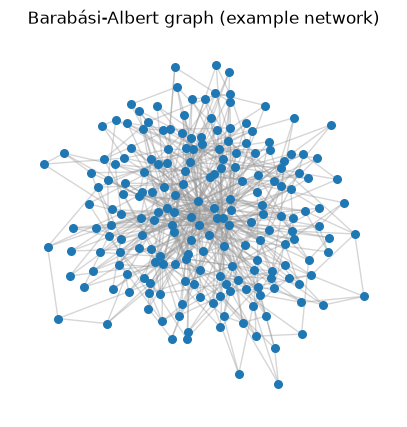

In [3]:
N = 200   # number of nodes
m = 3     # each new node attaches to m existing nodes

G_full = nx.barabasi_albert_graph(N, m, seed=SEED)

print(f"Number of nodes: {G_full.number_of_nodes()}")
print(f"Number of edges: {G_full.number_of_edges()}")

# Fix the layout once; the train/test figure below reuses pos so the nodes stay put
pos = nx.spring_layout(G_full, seed=SEED)


fig, ax = plt.subplots(1,1,figsize=(5,5),dpi=100)
nx.draw_networkx_nodes(G_full, pos, node_size=30, ax=ax)
nx.draw_networkx_edges(G_full, pos, alpha=0.4, edge_color='.6', ax=ax)
ax.set_axis_off()

ax.set_title("Barabási-Albert graph (example network)")

plt.show()

#### ...okay now what (your turn)

Before reading on, write down a plan as comments in the cell below. If all you had was this one graph, how would you build a test that a link-prediction method could pass or fail? What would count as a positive example, and what as a negative one? The next section gives one standard answer.


In [4]:
pass

____________

### Constructing a train/test split by hiding edges

To test a link predictor, we need pairs where we already know the answer: node pairs that *do* become edges and node pairs that *do not*. In truly temporal data we would use two snapshots, $G(t_0)$ and $G(t_1)$, and define positives as edges that appear between $t_0$ and $t_1$. In this chapter, however, we approximate this setting by **hiding** a random subset of edges from a single static graph.

The basic idea is:
1. Start from the original graph $G = (V, E)$.
2. Randomly select a fraction of existing edges to hold out as a **test set**, $E_{\text{test}} \subset E$.
3. Remove these edges from the graph to obtain a **training graph**, $ G_{\text{train}} = (V, E_{\text{train}})$ with $ E_{\text{train}} = E \setminus E_{\text{test}} $.
4. Treat each $(i, j) \in E_{\text{test}}$ as a *positive* example for evaluation.
5. Sample the same number of node pairs that are non-edges in the original graph $G$. Call this set $\mathcal{N}_{\text{test}}$; these are the *negative* examples.

All link prediction scores in this chapter will be computed on $G_{\text{train}}$. 

**The evaluation task is then: using only $G_{\text{train}}$, assign higher scores to the hidden edges in $E_{\text{test}}$ than to the sampled non-edges.**

**Note:** One subtlety is connectivity. If we remove edges arbitrarily, we may disconnect $G_{\text{train}}$ in ways that make the task less realistic or break methods that assume a single connected component. To avoid this, our splitting function can optionally avoid removing bridges (aka edges whose removal would disconnect the graph). When `ensure_connected=True`, we only hide non-bridge edges, so that $G_{\text{train}}$ remains connected.


The helper function below wraps all of this into a single call:

- Input: an undirected simple graph `G`, the fraction of edges to hide (`test_frac`), a random seed, and `ensure_connected` (skip bridges so `G_train` stays connected, assuming `G` starts out connected).
- Output:
  - `G_train`: the training graph with some edges removed,
  - `test_edges`: the list of hidden edges (positives),
  - `test_non_edges`: a sampled list of non-edges (negatives) of the same size.

We will reuse this function throughout the chapter to generate consistent train/test splits for different graphs and methods.


In [5]:
def train_test_split_graph(G, test_frac=0.2, seed=5, ensure_connected=True):
    """
    Create a train/test split of edges for link prediction.

    Parameters
    ----------
    G : nx.Graph
        Original undirected graph (assumed simple).
    test_frac : float
        Target fraction of edges to hide for testing (between 0 and 1).
    seed : int
        Random seed for reproducibility.
    ensure_connected : bool
        If True, avoid removing edges that would disconnect the training graph.
        If there are not enough non-bridge edges, fewer than test_frac * |E|
        edges will be removed.

    Returns
    -------
    G_train : nx.Graph
        Training graph with some edges removed.
    test_edges : list of (i, j)
        Edges that were removed and will be used as positive test examples.
    test_non_edges : list of (i, j)
        Node pairs that are not edges in the original graph, used as
        negative examples.
    """
    rng_local = np.random.default_rng(seed)

    # Work on a copy so we never mutate the original input graph
    G_train = G.copy()
    all_edges = list(G_train.edges())
    n_edges = len(all_edges)

    # Number of edges we will try to hide (may be fewer if we run out
    # of non-bridge edges when ensure_connected=True)
    n_test = int(test_frac * n_edges)

    # Randomize edge order so the choice of hidden edges is uniform-ish
    rng_local.shuffle(all_edges)
    test_edges = []

    if ensure_connected:
        # Remove edges one by one, skipping bridges to keep G_train connected
        for (i, j) in all_edges:
            if len(test_edges) >= n_test:
                break

            # Bridges change as we remove edges, so we recompute them each time
            # (fine for small/medium graphs; this is a teaching function)
            bridges = set(nx.bridges(G_train)) if nx.has_bridges(G_train) else set()

            # If this edge is currently a bridge, skip it to avoid disconnecting
            if (i, j) in bridges or (j, i) in bridges:
                continue

            # Otherwise, remove the edge and record it as a positive test example
            G_train.remove_edge(i, j)
            test_edges.append((i, j))
        # Note: if there are not enough non-bridge edges, test_edges may end up
        # shorter than n_test; we handle that naturally below.
    else:
        # Simple random edge hold-out: remove the first n_test shuffled edges
        test_edges = all_edges[:n_test]
        G_train.remove_edges_from(test_edges)

    # Sample negative examples (non-edges) from the *original* graph G.
    # Using G (not G_train) guarantees we never accidentally choose a hidden
    # positive edge as a "negative" example.
    non_edges = list(nx.non_edges(G))
    rng_local.shuffle(non_edges)

    # Take as many negatives as there are positives, so the test set is balanced
    test_non_edges = non_edges[: len(test_edges)]

    return G_train, test_edges, test_non_edges


In [6]:
G_train, test_edges, test_non_edges = train_test_split_graph(G_full, test_frac=0.2,
                                                     seed=SEED, ensure_connected=True)

print(f"Original graph edges: {G_full.number_of_edges()}")
print(f"Training graph edges: {G_train.number_of_edges()}")
print(f"Number of positive test edges: {len(test_edges)}")
print(f"Number of negative test non-edges: {len(test_non_edges)}")
print(f"Is G_train connected? {nx.is_connected(G_train)}")

Original graph edges: 591
Training graph edges: 473
Number of positive test edges: 118
Number of negative test non-edges: 118
Is G_train connected? True


Sanity check: 20% of 591 is 118.2, so we hide 118 edges, and 591 − 118 = 473 stay in `G_train`. It's still connected, and we have 118 non-edges to match the 118 hidden edges.

In [7]:
# A graph whose only edges are the sampled non-edges, so we can draw them (dashed red) in the middle panel below
non_G_plotting = nx.Graph()
non_G_plotting.add_nodes_from(G_full.nodes())
non_G_plotting.add_edges_from(test_non_edges)

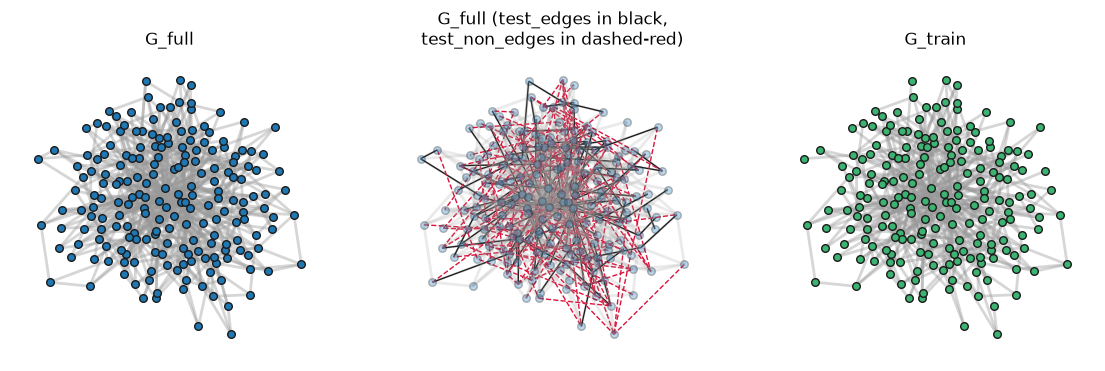

In [8]:
fig, ax = plt.subplots(1,3,figsize=(14,4),dpi=100)

nx.draw_networkx_nodes(G_full, pos, node_size=30, ax=ax[0], edgecolors='.1')
nx.draw_networkx_edges(G_full, pos, alpha=0.4, edge_color='.6', ax=ax[0], width=2)
ax[0].set_axis_off()
ax[0].set_title("G_full")

nx.draw_networkx_edges(G_full, pos, edgelist=test_edges, edge_color='k', ax=ax[1], width=1)
nx.draw_networkx_edges(non_G_plotting, pos, edgelist=test_non_edges,
                       edge_color='crimson', ax=ax[1], width=1, style='--')
nx.draw_networkx_nodes(G_full, pos, node_size=30, ax=ax[1], alpha=0.3, edgecolors='.1')
nx.draw_networkx_edges(G_full, pos, alpha=0.2, edge_color='.6', ax=ax[1], width=2)
ax[1].set_axis_off()
ax[1].set_title("G_full (test_edges in black,\ntest_non_edges in dashed-red)")


nx.draw_networkx_nodes(G_train, pos, node_size=30, node_color='mediumseagreen', edgecolors='.1', ax=ax[2])
nx.draw_networkx_edges(G_train, pos, alpha=0.4, edge_color='.6', ax=ax[2], width=2)
ax[2].set_axis_off()
ax[2].set_title("G_train")



plt.show()

Many of the black hidden edges touch the hubs. A hub has lots of edges, so when we pick edges at random it's likely to lose one. The dashed red non-edges are picked uniformly from all pairs, so most of them join two low-degree nodes. Keep this in mind when we get to preferential attachment.

### Other practical considerations in constructing link prediction datasets

Our setup (hide a random 20% of the edges, sample the same number of non-edges) is the simplest version of the task. Real data complicates it in four ways.

1. **Temporal vs random splits.**
   Here we pretend that $G_{\text{full}}$ is a snapshot at time $t$ and we randomly remove edges to simulate "future" links. In genuinely temporal data, we would instead:

   * take an earlier snapshot $G(t_0)$ as the training graph,
   * define positives as new edges that appear by $t_1 > t_0$ but were absent at $t_0$,
   * sample negatives from pairs that remain non-edges at $t_1$.

   Random removal is convenient for teaching, but it can make a method look better than it would on a split that respects time.

2. **Class imbalance and negative sampling.**
   Non-edges vastly outnumber edges, so we score a sample of them rather than all of them. The extended note below works through the numbers.

3. **Candidate set restrictions.**
   Many methods implicitly assume that new edges tend to close triangles. A common evaluation variant restricts candidates to node pairs at distance two in $G_{\text{train}}$, i.e., pairs that already share at least one neighbor. This focuses attention on "plausible" links and avoids rewarding trivial behavior on pairs that are far apart.

4. **Transductive vs inductive prediction.**
   In this chapter we only predict links between nodes that already exist in $G_{\text{train}}$ (transductive). In some applications (for example, recommending items to a new user), we must predict edges incident to nodes that did not exist at training time (inductive), which typically requires node attributes or more flexible models.

These details matter whenever we compare methods across datasets or claim that one algorithm outperforms another (see, e.g., the survey by [Lü and Zhou, 2011](https://www.sciencedirect.com/science/article/pii/S037843711000991X)).
__________

## Extended note: Class imbalance in link prediction

A structural feature of link prediction problems is that they are **extremely imbalanced**. Here a "class" just means a label: edge or non-edge. In a simple undirected graph with $n$ nodes, there are

$$
\binom{n}{2} = \frac{n(n-1)}{2}
$$

possible node pairs. Only $m$ of these pairs are observed edges; the rest are non-edges. In most real networks $m \ll \binom{n}{2}$, so the fraction of pairs that are connected is tiny.

For example, if $n = 10^5$ and $m = 10^6$, then:

* the number of possible pairs is about $5 \times 10^{9}$,
* the edge density $m / \binom{n}{2}$ is about $2 \times 10^{-4}$,
* for every positive (an actual or future edge) there are about five thousand negatives (pairs that never connect).




### Why we artificially balance positives and negatives

Throughout this notebook, we build balanced test sets by:

* hiding a subset of edges as positives (for example, $|E_{\text{test}}|$ edges), and
* sampling an equal number of non-edges as negatives.

This artificial balancing is useful for teaching and small-scale experiments:

1. It keeps the dataset size manageable: we do not need to score all $O(n^2)$ non-edges.
2. It avoids trivial baselines that achieve nearly perfect accuracy by predicting "no edge" almost everywhere.
3. It gives a fixed reference point: on a balanced set, a random ranking scores about 0.5 on both ROC-AUC and precision@$k$ (both defined below).

The two metrics react differently to balancing, though. ROC-AUC compares positives with negatives one pair at a time, so it does not depend on how many negatives there are: with uniformly sampled negatives it estimates the AUC we would get on all non-edges. Precision@$k$ and average precision do depend on the ratio, and on all non-edges of a sparse graph they are far lower than on a balanced set.

### Why *accuracy* is misleading

Consider a classifier that predicts "no link" for every candidate pair: if we evaluate it on all pairs $(i,j)$, its accuracy is extremely high (close to 1), because almost all pairs are non-edges... but it is useless for link prediction, because it never finds any new edges.

Even on balanced test sets, accuracy can be a weak indicator of ranking quality. This is why link prediction work typically reports ranking metrics (ROC-AUC, precision@$k$, average precision) rather than raw accuracy. More on this soon!

Because we rarely evaluate on all non-edges, we must decide which *negatives to sample*. Different choices answer different questions:

* Uniform negative sampling asks whether the method can separate future edges from "typical" non-edges.
* Distance-restricted sampling focuses on deciding which open triads will close.
* Popularity- or exposure-aware sampling is common in recommendation systems, where not all non-edges are equally "negative".

The final numerical value of ROC-AUC or precision@$k$ should always be interpreted relative to how the negative examples were constructed.
_____________

## Let's predict some missing links!
... okay, how?

### Classical neighborhood-based link prediction scores

Most of the classic link predictors start from one idea:

> Two nodes are more likely to form a link if they have many neighbors in common or if they are embedded in similar local neighborhoods.

In social networks, this is the notion of *triadic closure* (i.e., the "friends of my friends are likely to become my friends.") In other domains, it corresponds to functional similarity (two neurons that interact with many of the same partners may be part of the same cluster) or topical relatedness (two web pages that are connected by many others may cover similar content).

For an undirected graph, let $\Gamma(i)$ denote the set of neighbors of node $i$, and let $k_i = |\Gamma(i)|$ be its degree. The simplest neighborhood-based link prediction scores are functions of overlaps between $\Gamma(i)$ and $\Gamma(j)$ and the degrees of $i$, $j$, and their common neighbors. **THERE ARE SO MANY LINK PREDICTION ALGORITHMS,** but let's focus on five canonical ones here.



1. **Common neighbors (CN)**
    The most direct measure simply counts how many neighbors $i$ and $j$ share:

    $$
    s_{\text{CN}}(i, j) = |\Gamma(i) \cap \Gamma(j)|
    $$
    
    This implements the pure triadic-closure intuition: the more common neighbors two nodes have, the more opportunities there have been for a link to form between them. In early empirical work on co-authorship networks, Liben-Nowell and Kleinberg (2007) found that common neighbors alone can already perform surprisingly well.



2. **Jaccard coefficient**
    Common neighbors can be biased toward high-degree nodes: two hubs may share many neighbors simply because they each have many neighbors. The **Jaccard coefficient** normalizes by the size of the union:

    $$
    s_{\text{Jaccard}}(i, j)
    = \frac{|\Gamma(i) \cap \Gamma(j)|}{|\Gamma(i) \cup \Gamma(j)|}
    $$
    
    This is identical to the Jaccard similarity from information retrieval, applied to neighbor sets. It assigns a high score only when the shared neighbors form a large *fraction* of the nodes' combined neighborhoods, not just a large absolute count.




3. **Adamic-Adar index (AA)**
   The **Adamic-Adar index** (Adamic and Adar, 2003) refines common neighbors by downweighting common neighbors that are themselves very high-degree hubs:

   $$
   s_{\text{AA}}(i, j)
   = \sum_{l \in \Gamma(i) \cap \Gamma(j)} \frac{1}{\log k_l}
   $$

   The idea is that a common neighbor $l$ that is connected to *everyone* carries less specific information about similarity between $i$ and $j$ than a rare, low-degree neighbor. Every common neighbor $l$ is linked to both $i$ and $j$, so $k_l \ge 2$ and $\log k_l > 0$: the formula never divides by zero. The logarithm makes the penalty grow slowly with degree: a common neighbor of degree 100 counts about 0.15 times as much as one of degree 2 ($1/\ln 100 \approx 0.22$ against $1/\ln 2 \approx 1.44$).




4. **Preferential attachment (PA)**
    The **preferential attachment** score uses only the degrees of $i$ and $j$:
    
    $$
    s_{\text{PA}}(i, j) = k_i\,k_j
    $$
    
    This is motivated by preferential attachment (Albert and Barabási, 2002): high-degree nodes gain new neighbors faster. In scientific collaboration networks, the chance that two scientists start co-authoring grows with the product of their numbers of collaborators (Newman, 2001; Barabási et al., 2002). The BA model itself is a bit different: every new edge has a newcomer at one end, so in the model hubs gain edges from newcomers, not from each other. Unlike the previous scores, PA does *not* look at common neighbors at all; it purely encodes the rich-getting-richer effect.




5. **Resource allocation index (RA)**
    The **resource allocation** index (Zhou, Lü, and Zhang, 2009) is similar in spirit to Adamic-Adar but uses a $1/k_l$ penalty instead of $1/\log k_l$:

    $$
    s_{\text{RA}}(i, j)
    = \sum_{l \in \Gamma(i) \cap \Gamma(j)} \frac{1}{k_l}
    $$
    
    This can be interpreted as a simple diffusion or resource-sharing process: imagine each common neighbor $l$ has one unit of "resource" and distributes it equally among its neighbors. The amount of resource that flows from $i$ to $j$ via $l$ is then $1/k_l$. Summing over all common neighbors measures how much resource $i$ could send to $j$ through paths of length two. Compared to Adamic-Adar, the $1/k_l$ penalty is stronger for high-degree nodes: a common neighbor of degree 100 counts $2/100 = 0.02$ times as much as one of degree 2, against 0.15 under Adamic-Adar. So RA emphasizes rare, low-degree common neighbors even more.




All five scores are **local**: they depend only on the immediate neighborhoods of $i$ and $j$. Four of them (all but preferential attachment) give higher scores to pairs whose neighborhoods overlap; PA gives two hubs a high score even if they share no neighbors. They are symmetric in $i$ and $j$, and they can be computed for any non-edge $(i,j)$ without fitting a global model.

These are the standard baselines in the field, and they often hold their own against much more complicated methods (Liben-Nowell and Kleinberg, 2007; Lü and Zhou, 2011; Zhou, Lü, and Zhang, 2009). Let's write each one as a Python function.

Tiny graph time. Nodes $i$ and $j$ have two common neighbors: $a$, which has degree 2 (it only knows $i$ and $j$), and $h$, a hub with degree 10. Say $k_i = 3$ and $k_j = 4$, so $|\Gamma(i) \cup \Gamma(j)| = 5$. Then CN $= 2$, Jaccard $= 2/5 = 0.4$, AA $= 1/\log 2 + 1/\log 10 \approx 1.44 + 0.43 = 1.88$, RA $= 1/2 + 1/10 = 0.6$, and PA $= 3 \times 4 = 12$. Most of AA and RA comes from $a$, the neighbor nobody else knows.

### Your turn!

Fill in the five functions below. Each takes a graph `G` and two nodes `i` and `j` and returns one number (a float). You'll need `G.neighbors(i)`, `G.degree[i]`, Python's set operations `&` and `|`, and `np.log`. When you're done, run the check cell after `resource_allocation_score`.

```
1. common_neighbors_score
2. jaccard_score
3. adamic_adar_score
4. preferential_attachment_score
5. resource_allocation_score
```

In [9]:
def common_neighbors_score(G, i, j):
    """
    Compute the common-neighbors score between nodes i and j.

    s_CN(i, j) = |Γ(i) ∩ Γ(j)|

    Parameters
    ----------
    G : nx.Graph
        Undirected simple graph.
    i, j : int
        Node identifiers.

    Returns
    -------
    float
        Common-neighbors score between i and j.
    """
    # TODO:
    # 1. Get the neighbor sets of i and j.
    # 2. Compute the size of their intersection.
    # 3. Return that value as a float.

    pass

In [10]:
def jaccard_score(G, i, j):
    """
    Compute the Jaccard coefficient between nodes i and j.

    s_Jaccard(i, j) = |Γ(i) ∩ Γ(j)| / |Γ(i) ∪ Γ(j)|

    If both nodes have no neighbors (empty union), define the score to be 0.0.

    Parameters
    ----------
    G : nx.Graph
        Undirected simple graph.
    i, j : int
        Node identifiers.

    Returns
    -------
    float
        Jaccard similarity between the neighbor sets of i and j.
    """
    # TODO:
    # 1. Get Γ(i) and Γ(j) as Python sets.
    # 2. Compute the intersection and union of these sets.
    # 3. If the union is empty, return 0.0.
    # 4. Otherwise, return |intersection| / |union| as a float.
    
    pass

In [11]:
def adamic_adar_score(G, i, j):
    """
    Compute the Adamic-Adar index between nodes i and j.

    s_AA(i, j) = sum_{l in Γ(i) ∩ Γ(j)} 1 / log(k_l)

    where k_l is the degree of the common neighbor l. A common neighbor is
    linked to both i and j, so k_l >= 2 and log(k_l) > 0.

    Parameters
    ----------
    G : nx.Graph
        Undirected simple graph.
    i, j : int
        Node identifiers.

    Returns
    -------
    float
        Adamic-Adar score between i and j.
    """
    # TODO:
    # 1. Get Γ(i) and Γ(j) and compute their intersection (common neighbors).
    # 2. For each common neighbor l:
    #       - Compute its degree k_l.
    #       - Add 1 / log(k_l) to a running sum.
    # 3. Return the final sum as a float.
    
    pass

In [12]:
def preferential_attachment_score(G, i, j):
    """
    Compute the preferential-attachment score between nodes i and j.

    s_PA(i, j) = k_i * k_j

    where k_i and k_j are the degrees of i and j.

    Parameters
    ----------
    G : nx.Graph
        Undirected simple graph.
    i, j : int
        Node identifiers.

    Returns
    -------
    float
        Preferential-attachment score between i and j.
    """
    # TODO:
    # 1. Get the degrees of i and j from G.
    # 2. Return their product as a float.
    
    pass

In [13]:
def resource_allocation_score(G, i, j):
    """
    Compute the resource allocation index between nodes i and j.

    s_RA(i, j) = sum_{l in Γ(i) ∩ Γ(j)} 1 / k_l

    where k_l is the degree of the common neighbor l.

    Parameters
    ----------
    G : nx.Graph
        Undirected simple graph.
    i, j : int
        Node identifiers.

    Returns
    -------
    float
        Resource-allocation score between i and j.
    """
    # TODO:
    # 1. Get Γ(i) and Γ(j) and compute their intersection (common neighbors).
    # 2. For each common neighbor l:
    #       - Compute its degree k_l.
    #       - Add 1 / k_l to a running sum.
    # 3. Return the final sum as a float.
    
    pass

In [14]:
# Check your functions on the tiny graph from above: i and j share a (degree 2) and h (degree 10)
G_tiny = nx.Graph()
G_tiny.add_edges_from([('i','a'), ('j','a'), ('i','h'), ('j','h'), ('i','x'), ('j','y'), ('j','z')])
G_tiny.add_edges_from(('h', f'leaf{t}') for t in range(8))   # 8 more neighbors give h degree 10

expected = {common_neighbors_score: 2.0, jaccard_score: 0.4, adamic_adar_score: 1.877,
            preferential_attachment_score: 12.0, resource_allocation_score: 0.6}
for fn, target in expected.items():
    got = fn(G_tiny, 'i', 'j')
    if got is None:
        print(f"{fn.__name__:30s} not written yet")
    else:
        status = "ok" if abs(got - target) < 1e-3 else "CHECK THIS"
        print(f"{fn.__name__:30s} {got:.3f}  (expected {target})  {status}")

common_neighbors_score         not written yet
jaccard_score                  not written yet
adamic_adar_score              not written yet
preferential_attachment_score  not written yet
resource_allocation_score      not written yet


In [15]:
pass

Don't look below! Solutions are in the next cell. Try the five functions first and run the check above. Running the solution cell replaces your versions with mine, so everything below works whether or not you finished.

________

In [16]:
def common_neighbors_score(G, i, j):
    """
    Compute the common-neighbors score between nodes i and j.

    s_CN(i, j) = |Γ(i) ∩ Γ(j)|,

    where Γ(i) is the set of neighbors of i.

    Parameters
    ----------
    G : networkx.Graph
        Undirected simple graph.
    i, j
        Node identifiers.

    Returns
    -------
    float
        Number of common neighbors between i and j.
    """
    # Neighbor sets of each node
    neighbors_i = set(G.neighbors(i))
    neighbors_j = set(G.neighbors(j))

    # Intersection of neighbor sets
    common = neighbors_i & neighbors_j

    return float(len(common))


def jaccard_score(G, i, j):
    """
    Compute the Jaccard coefficient between nodes i and j.

    s_Jaccard(i, j) = |Γ(i) ∩ Γ(j)| / |Γ(i) ∪ Γ(j)|.

    If both nodes have no neighbors (empty union), the score is defined as 0.0.

    Parameters
    ----------
    G : networkx.Graph
        Undirected simple graph.
    i, j
        Node identifiers.

    Returns
    -------
    float
        Jaccard similarity between the neighbor sets of i and j.
    """
    # Neighbor sets of each node
    neighbors_i = set(G.neighbors(i))
    neighbors_j = set(G.neighbors(j))

    # Intersection and union of neighbor sets
    intersection = neighbors_i & neighbors_j
    union = neighbors_i | neighbors_j

    # If both nodes are isolated, define similarity to be 0
    if not union:
        return 0.0

    return len(intersection) / len(union)


def adamic_adar_score(G, i, j):
    """
    Compute the Adamic-Adar index between nodes i and j.

    s_AA(i, j) = sum_{l in Γ(i) ∩ Γ(j)} 1 / log(k_l),

    where k_l is the degree of the common neighbor l.
    A common neighbor is linked to both i and j, so k_l >= 2 and log(k_l) > 0.

    Parameters
    ----------
    G : networkx.Graph
        Undirected simple graph.
    i, j
        Node identifiers.

    Returns
    -------
    float
        Adamic-Adar score between i and j.
    """
    # Neighbor sets and common neighbors
    neighbors_i = set(G.neighbors(i))
    neighbors_j = set(G.neighbors(j))
    common_neighbors = neighbors_i & neighbors_j

    score = 0.0

    # Accumulate 1 / log(k_l) across common neighbors
    for ell in common_neighbors:
        k_ell = G.degree[ell]
        # k_ell >= 2 for any common neighbor, so the log is positive; the check is only a guard
        if k_ell > 1:
            score += 1.0 / np.log(k_ell)

    return score


def preferential_attachment_score(G, i, j):
    """
    Compute the preferential-attachment score between nodes i and j.

    s_PA(i, j) = k_i * k_j,

    where k_i and k_j are the degrees of i and j.

    Parameters
    ----------
    G : networkx.Graph
        Undirected simple graph.
    i, j
        Node identifiers.

    Returns
    -------
    float
        Preferential-attachment score between i and j.
    """
    k_i = G.degree[i]
    k_j = G.degree[j]

    return float(k_i * k_j)


def resource_allocation_score(G, i, j):
    """
    Compute the resource allocation (RA) index between nodes i and j.

    s_RA(i, j) = sum_{l in Γ(i) ∩ Γ(j)} 1 / k_l,

    where k_l is the degree of the common neighbor l.

    Parameters
    ----------
    G : networkx.Graph
        Undirected simple graph.
    i, j
        Node identifiers.

    Returns
    -------
    float
        Resource-allocation score between i and j.
    """
    # Neighbor sets and common neighbors
    neighbors_i = set(G.neighbors(i))
    neighbors_j = set(G.neighbors(j))
    common_neighbors = neighbors_i & neighbors_j

    score = 0.0

    # Accumulate 1 / k_l across common neighbors
    for ell in common_neighbors:
        k_ell = G.degree[ell]
        if k_ell > 0:
            score += 1.0 / k_ell

    return score


_______

#### What do these scores even look like?
Let's start by looking at the Jaccard scores of the hidden edges (positives) and of the sampled non-edges (negatives)...

In [17]:
# Jaccard score of every hidden edge, computed on the training graph
pos_scores_jac = [jaccard_score(G_train, i, j) for (i, j) in test_edges]

In [18]:
# ...and of every sampled non-edge
neg_scores_jac = [jaccard_score(G_train, i, j) for (i, j) in test_non_edges]

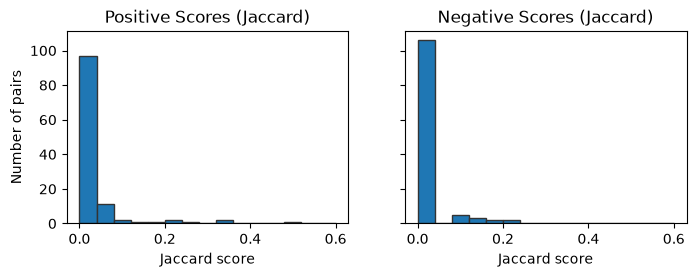

In [19]:
fig, ax = plt.subplots(1,2,figsize=(8,2.5),dpi=100,sharex=True,sharey=True)

# Jaccard is between 0 and 1; the largest score on this split is 0.5, so bins up to 0.6 cover everything
bins = np.linspace(0, 0.6, 16)
ax[0].hist(pos_scores_jac, bins=bins, ec='.2')
ax[1].hist(neg_scores_jac, bins=bins, ec='.2')
ax[0].set_xlabel('Jaccard score'); ax[1].set_xlabel('Jaccard score'); ax[0].set_ylabel('Number of pairs')

ax[0].set_title('Positive Scores (Jaccard)')
ax[1].set_title('Negative Scores (Jaccard)')

plt.show()

Both panels have a tall bar at zero. Most pairs, hidden edge or not, share no neighbors at all in `G_train`, so their Jaccard score is exactly 0. In this graph that is true of 70% of the hidden edges and 89% of the sampled non-edges. Whatever separation Jaccard achieves comes from the minority of pairs with a nonzero score.

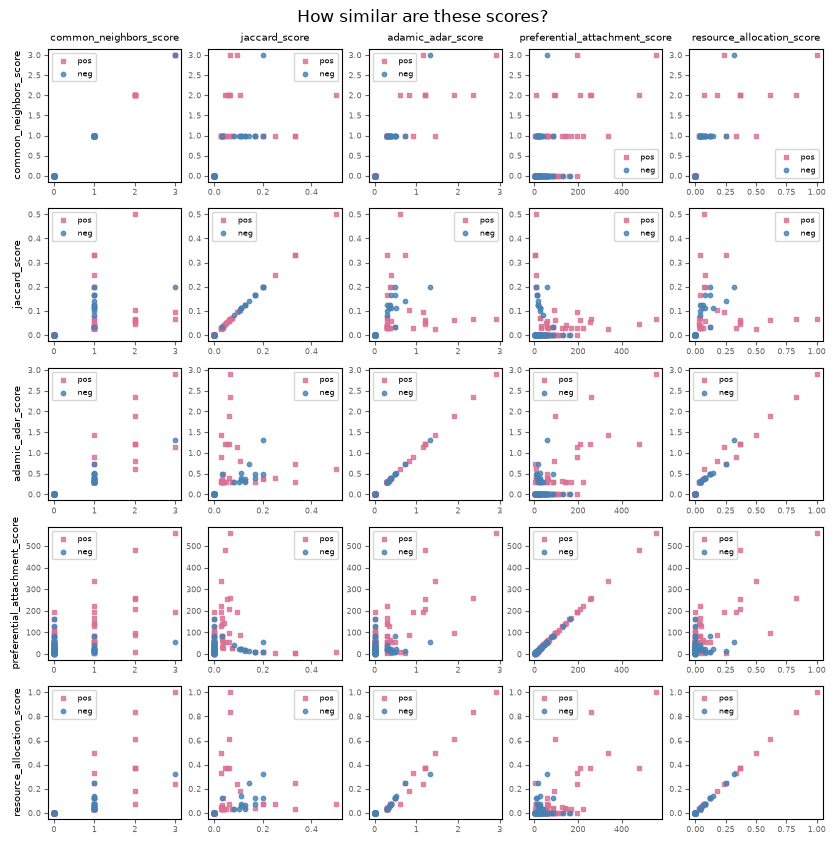

In [20]:
# Each panel plots one score against another for the same pairs: hidden edges in pink, sampled
# non-edges in blue. The diagonal panels plot a score against itself.
fig, ax = plt.subplots(5,5,figsize=(10,10),dpi=100)

labels = ['common_neighbors_score', 'jaccard_score', 'adamic_adar_score',
          'preferential_attachment_score', 'resource_allocation_score']
for i1, func1 in enumerate([common_neighbors_score, jaccard_score, adamic_adar_score,
                           preferential_attachment_score, resource_allocation_score]):
    
    pos_scores1 = [func1(G_train, i, j) for (i, j) in test_edges]
    neg_scores1 = [func1(G_train, i, j) for (i, j) in test_non_edges]

    for i2, func2 in enumerate([common_neighbors_score, jaccard_score, adamic_adar_score,
                               preferential_attachment_score, resource_allocation_score]):

        pos_scores2 = [func2(G_train, i, j) for (i, j) in test_edges]
        neg_scores2 = [func2(G_train, i, j) for (i, j) in test_non_edges]
        
        
        ax[i1,i2].scatter(pos_scores2, pos_scores1, s=10, marker='s',
                          c='palevioletred', label='pos', alpha=0.8)
        ax[i1,i2].scatter(neg_scores2, neg_scores1, s=10, marker='o',
                          c='steelblue', label='neg', alpha=0.8)
        
        if i1==0:
            ax[i1,i2].set_title(labels[i2],fontsize='x-small')

        if i2==0:
            ax[i1,i2].set_ylabel(labels[i1],fontsize='x-small')
            
        ax[i1,i2].tick_params(which='both', length=3, pad=2, labelsize='xx-small',
                              labelcolor='.4', color='.4')
        ax[i1,i2].legend(fontsize='xx-small')


plt.suptitle('How similar are these scores?', y=0.92)

plt.show()

Adamic-Adar and resource allocation fall almost on a line against each other: they weight the same common neighbors slightly differently, so they rank pairs in nearly the same order. Common neighbors only counts, so against either of them its points stack in columns at 1, 2 and 3. Preferential attachment looks nothing like the other four, because it ignores common neighbors and uses only the two degrees.

### Evaluating a scoring function

Once we define a link-prediction score $s(i, j)$, we need a way to quantify how well it separates true future edges from non-edges. Given a training graph $G_{\text{train}}$, a set of hidden **positive** edges (the test edges), and a set of sampled **negative** pairs (non-edges), we can:

1. compute a score for each positive and negative example using our chosen function `score_fn(G, i, j)`,
2. build a label vector with 1 for positives and 0 for negatives,
3. compare the scores with the labels using ROC-AUC (defined just below).

The helper function below wraps this pattern: it takes a training graph, lists of positive and negative pairs, and a scoring function, and returns the labels, the scores, and the ROC-AUC value (optionally printing it as well). We will reuse this for all of the neighborhood-based scores in this chapter.



#### Evaluation Technique: ROC-AUC 

Given a score function $s(i, j)$, we can evaluate it on our labeled examples:

* For each positive test edge $(i, j) \in E_{\text{test}}$, compute its score.
* For each negative test pair $(i, j) \in \mathcal{N}_{\text{test}}$ (sampled non-edges), compute its score.

Ideally, a hidden edge gets a higher score than a non-edge most of the time.

To draw the ROC curve, pick a threshold $\tau$ and call every pair with $s(i,j) > \tau$ an edge. The **true positive rate** (TPR) is the fraction of hidden edges above $\tau$, and the **false positive rate** (FPR) is the fraction of non-edges above $\tau$. Sliding $\tau$ from very high to very low traces a curve from $(0,0)$ to $(1,1)$, and ROC-AUC is the area under it (Fawcett, 2006). The AUC has a useful interpretation:

> The AUC is the probability that a randomly chosen positive example receives a higher score than a randomly chosen negative example, counting ties as half: $\text{AUC} = P(s_+ > s_-) + \tfrac{1}{2} P(s_+ = s_-)$.

A small example: three hidden edges score 3, 2, 0 and three non-edges score 1, 0, 0. Of the 9 positive-negative pairs, the 3 and the 2 each beat all three non-edges (6 wins), and the 0 loses to the 1 and ties the two 0s (two half-wins). So AUC $= (6+1)/9 = 0.78$. Sanity check: `roc_auc_score([1,1,1,0,0,0], [3,2,0,1,0,0])` gives 0.778. Ties will matter a lot below, because many pairs share no neighbors and score exactly 0.

An AUC of $0.5$ corresponds to random guessing; an AUC of $1.0$ is perfect ranking.

__________

In [21]:
def evaluate_score_function(G_train, test_edges, test_non_edges, score_fn, verbose=True):
    """
    Evaluate a link-prediction scoring function using ROC-AUC.

    Parameters
    ----------
    G_train : networkx.Graph
        Training graph used to compute scores.
    test_edges : list of (i, j)
        Positive examples (edges that were removed from the original graph).
    test_non_edges : list of (i, j)
        Negative examples (node pairs that are non-edges in the original graph).
    score_fn : callable
        Function of the form score_fn(G, i, j) -> float.
    verbose : bool, optional
        If True, print the AUC value.

    Returns
    -------
    y_true : numpy.ndarray
        Labels: 1 for each pair in test_edges, then 0 for each pair in test_non_edges.
    y_scores : numpy.ndarray
        score_fn applied to the same pairs in the same order (positives first).
    auc : float
        ROC-AUC value.
    """
    # Scores for positive examples
    pos_scores = [score_fn(G_train, i, j) for (i, j) in test_edges]

    # Scores for negative examples
    neg_scores = [score_fn(G_train, i, j) for (i, j) in test_non_edges]

    # True labels: 1 for positives, 0 for negatives
    y_true = np.array([1] * len(pos_scores) + [0] * len(neg_scores))

    # Concatenate scores in the same order as labels
    y_scores = np.array(pos_scores + neg_scores)

    # Compute ROC-AUC
    auc = roc_auc_score(y_true, y_scores)

    if verbose:
        print(f"AUC = {auc:.3f}")

    return y_true, y_scores, auc


In [22]:
print("BA graph: Common neighbors:")
y_cn, scores_cn, auc_cn = evaluate_score_function(
    G_train, test_edges, test_non_edges, common_neighbors_score
)
print()
print("BA graph: Jaccard:")
y_jac, scores_jac, auc_jac = evaluate_score_function(
    G_train, test_edges, test_non_edges, jaccard_score
)

print()
print("BA graph: Adamic-Adar:")
y_aa, scores_aa, auc_aa = evaluate_score_function(
    G_train, test_edges, test_non_edges, adamic_adar_score
)

print()
print("BA graph: Preferential attachment:")
y_pa, scores_pa, auc_pa = evaluate_score_function(
    G_train, test_edges, test_non_edges, preferential_attachment_score
)

print()
print("BA graph: Resource allocation:")
y_ra, scores_ra, auc_ra = evaluate_score_function(
    G_train, test_edges, test_non_edges, resource_allocation_score
)


BA graph: Common neighbors:
AUC = 0.596

BA graph: Jaccard:
AUC = 0.585

BA graph: Adamic-Adar:
AUC = 0.592

BA graph: Preferential attachment:
AUC = 0.673

BA graph: Resource allocation:
AUC = 0.592


Preferential attachment has the highest AUC, mostly because of how we built the test set rather than how the BA model grows. A hidden edge is a randomly chosen edge, and a randomly chosen edge is much more likely to touch a hub than a randomly chosen pair is. Here the average $k_i k_j$ is about 60 for the hidden edges and about 19 for the sampled non-edges. Any graph with hubs hands PA this advantage, and we'll see it again on the Karate Club. (Change `SEED` and rerun: for seeds 0 through 99, PA comes out on top every time.) The four neighborhood scores sit close to 0.6, barely above guessing. That's the zero bar from the histograms again. Each new node in this BA graph brings only 3 edges, so few triangles form, and most positives and negatives tie at a score of 0. ROC-AUC counts each tied positive-negative pair as half right.

### Visualizing performance: ROC curves

A single AUC number doesn't tell us where in the ranking a method does well. Two methods can have similar AUC while one is much better among its top-scored pairs, which shows up at low false positive rates. Let's plot the curves.

In settings like recommendation, we often care most about the left part of the ROC curve: how many true positives we can recover before we start incurring many false positives.


In [23]:
# Scores from the BA evaluation cell above (scores_cn ... scores_ra), positives first, then negatives
score_dict = {
    "Common neighbors": scores_cn,
    "Jaccard": scores_jac,
    "Adamic-Adar": scores_aa,
    "Preferential attachment": scores_pa,
    "Resource allocation": scores_ra,
}

In [24]:
# The labels are the same for every method (1 for the hidden edges, 0 for the non-edges)
y_true = y_cn.copy()

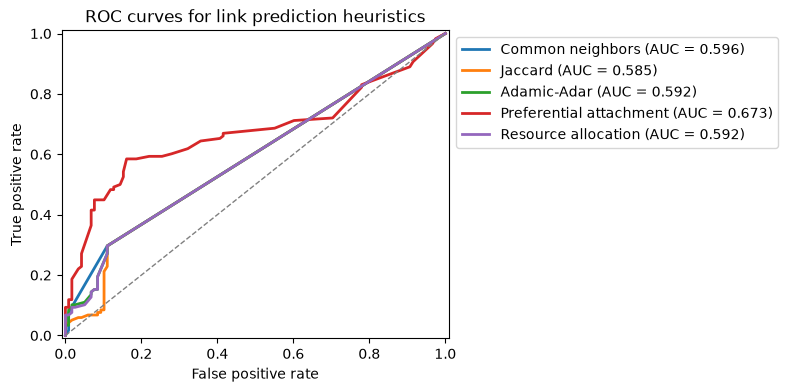

In [25]:
def plot_roc_curves(y_true, score_dict, title):
    """
    Draw one ROC curve per method on a single set of axes.

    Parameters
    ----------
    y_true : numpy.ndarray of 0/1
        Labels shared by every method (1 = hidden edge, 0 = sampled non-edge).
    score_dict : dict
        Maps a method name to its array of scores, in the same order as y_true.
    title : str
        Title for the plot.
    """
    fig, ax = plt.subplots(1, 1, figsize=(5, 4), dpi=100)
    for name, scores in score_dict.items():
        fpr, tpr, _ = roc_curve(y_true, scores)
        auc = roc_auc_score(y_true, scores)
        ax.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})", lw=2)
    ax.plot([0, 1], [0, 1], linestyle="--", linewidth=1, color=".5")   # random guessing
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
    ax.set_title(title)
    ax.legend(bbox_to_anchor=[1.0, 1.0], loc=2)
    ax.set_xlim(-0.01, 1.01)
    ax.set_ylim(-0.01, 1.01)
    plt.show()


plot_roc_curves(y_true, score_dict, "ROC curves for link prediction heuristics")

Notice the shape of the four neighborhood curves: a steep climb at the far left, then one long straight line from about $(0.11, 0.30)$ to $(1, 1)$. The climb is the 48 pairs with at least one common neighbor. The straight line is the 188 pairs tied at a score of 0. No threshold can split a tie, so the curve crosses that whole block in one straight step, which is what you'd get by ordering those pairs at random. Preferential attachment spreads its scores over many values, so its curve bends instead.

__________
### Other structural link prediction scores

The heuristics above are part of a larger family of structurally defined similarity measures (Liben-Nowell and Kleinberg, 2007; Lü and Zhou, 2011), including:

* **Salton index (cosine similarity):**

    $$
    s_{\text{Salton}}(i, j)
    = \frac{|\Gamma(i) \cap \Gamma(j)|}{\sqrt{k_i\,k_j}}
    $$

* **Sørensen index:**

    $$
    s_{\text{Sørensen}}(i, j)
    = \frac{2\,|\Gamma(i) \cap \Gamma(j)|}{k_i + k_j}
    $$

* **Hub-promoted and hub-depressed indices:**

    $$
    s_{\text{HPI}}(i, j)
    = \frac{|\Gamma(i) \cap \Gamma(j)|}{\min\{k_i, k_j\}} ,
    \qquad
    s_{\text{HDI}}(i, j)
    = \frac{|\Gamma(i) \cap \Gamma(j)|}{\max\{k_i, k_j\}}
    $$

Most of these differ only in how they normalize the common-neighbors count. Empirically, several of them achieve similar performance on social and information networks, and Common Neighbors, Jaccard, Adamic-Adar, and Resource Allocation often serve as representative baselines.


### Global similarity measures

The heuristics above depend only on the immediate neighborhoods of $i$ and $j$. One can also define **global** similarity measures that take into account paths of all lengths in the network. A classical example is the Katz index (Katz, 1953). Let $A$ be the adjacency matrix of $G$. For nodes $i$ and $j$, the Katz similarity is

$$
s_{\text{Katz}}(i, j)
= \sum_{l = 1}^{\infty} \beta^l \big[A^l\big]_{ij}
$$

where $\beta > 0$ is a decay parameter and $\big[A^l\big]_{ij}$ counts the number of walks of length $l$ from $i$ to $j$. Short walks contribute more than long walks, and all walks are downweighted by $\beta^l$. The sum converges only when $\beta < 1/\lambda_{\max}$, where $\lambda_{\max}$ is the largest eigenvalue of $A$; then it has the closed form $S_{\text{Katz}} = (I - \beta A)^{-1} - I$. In practice one truncates the series at some maximum length or solves the linear system instead of inverting the matrix.

Random-walk-based scores, such as those derived from personalized PageRank or commute times, follow a similar spirit: they use properties of random walks on the graph to quantify how easily information can flow between two nodes. These global measures are more computationally demanding than local heuristics but can capture long-range structural information that local measures miss.
__________

## Ranking quality and precision at top-$k$

In many applications, we are not forced to classify all candidate pairs. Instead, we only act on the highest-scoring predictions, such as:

* recommending the top 10 new friends to each user,
* suggesting the top 50 potential collaboration links,
* prioritizing the top 100 candidate interactions for experimental validation.

In these scenarios, **precision at top-$k$** is often more meaningful than AUC. For a given $k$:

1. Sort the candidate pairs by their scores in descending order (breaking ties at random).
2. Take the top $k$ pairs.
3. Compute

$$
\text{Precision@}k = \frac{\text{number of true edges among the top } k \text{ pairs}}{k}.
$$

High precision at small $k$ indicates that the method is very good at identifying the most promising candidates.

One thing to keep in mind below: our "candidate pairs" are the balanced test set, the hidden edges plus an equal number of sampled non-edges. Half of them are positives, so a method that ranks pairs at random already gets a precision@$k$ of about 0.5. On the full set of non-edges, where positives are rare, the same method would score far lower.

In [26]:
def precision_at_k(y_true, y_scores, k, seed=0):
    """
    Compute precision at top-k.

    Ties are broken at random (with a fixed seed). Many of our scores are exactly
    0 for most pairs, and without this the order in which we happened to list the
    pairs (positives first) would decide who makes the top k.

    Parameters
    ----------
    y_true : array-like
        True labels (1 for positive, 0 for negative).
    y_scores : array-like
        Scores for each example (higher means more likely positive).
    k : int
        Number of top predictions to consider.
    seed : int, optional
        Seed for the random tie-breaking.

    Returns
    -------
    float
        Fraction of the top-k scored examples that are actually positive.
    """
    y_true = np.asarray(y_true)
    y_scores = np.asarray(y_scores)

    if k <= 0:
        raise ValueError("k must be positive")

    # Do not ask for more than we have
    k = min(k, len(y_true))

    # Shuffle first, then sort by score with a stable sort: pairs with equal
    # scores stay in the shuffled (random) order
    rng_ties = np.random.default_rng(seed)
    perm = rng_ties.permutation(len(y_scores))
    idx_sorted = perm[np.argsort(-y_scores[perm], kind="stable")]

    # Take the top-k indices and compute the fraction that are positive
    topk_idx = idx_sorted[:k]

    return y_true[topk_idx].sum() / k

In [27]:
# Precision@k for each method at a few values of k (random ranking would give about 0.5)
ks = [5, 10, 20, 50]

methods = {
    "Common neighbors": (y_cn, scores_cn),
    "Jaccard": (y_jac, scores_jac),
    "Adamic-Adar": (y_aa, scores_aa),
    "Preferential attachment": (y_pa, scores_pa),
    "Resource allocation": (y_ra, scores_ra),
}

for name, (y, scores) in methods.items():
    print(f"\n{name}:")
    for k in ks:
        p_at_k = precision_at_k(y, scores, k)
        print(f"  Precision@{k:2d} = {p_at_k:.3f}")



Common neighbors:
  Precision@ 5 = 0.800
  Precision@10 = 0.900
  Precision@20 = 0.800
  Precision@50 = 0.720

Jaccard:
  Precision@ 5 = 1.000
  Precision@10 = 0.700
  Precision@20 = 0.450
  Precision@50 = 0.720

Adamic-Adar:
  Precision@ 5 = 0.800
  Precision@10 = 0.900
  Precision@20 = 0.700
  Precision@50 = 0.720

Preferential attachment:
  Precision@ 5 = 1.000
  Precision@10 = 1.000
  Precision@20 = 0.900
  Precision@50 = 0.840

Resource allocation:
  Precision@ 5 = 1.000
  Precision@10 = 0.800
  Precision@20 = 0.650
  Precision@50 = 0.720


Preferential attachment stays near the top at every $k$. The four neighborhood scores bunch together by $k = 50$, because only 48 of the 236 test pairs share any neighbor in `G_train` (35 hidden edges and 13 non-edges). Past the top 48, every neighborhood score is choosing among pairs tied at 0, and `precision_at_k` breaks those ties at random.

### Even more ways to measure performance...

Accuracy, precision, recall and F1 need a threshold: call a pair an edge if its score is above some cutoff $\tau$. Then every test pair lands in one of four boxes. A true positive (TP) is a hidden edge we called an edge, a false positive (FP) is a non-edge we called an edge, a true negative (TN) is a non-edge we left out, and a false negative (FN) is a hidden edge we missed. The two AUCs at the end sweep that threshold over every value instead of fixing one.

- **Accuracy**  --- Fraction of correct predictions.  

    $$
    \text{Accuracy} = \frac{\text{TP} + \text{TN}}{\text{TP} + \text{FP} + \text{TN} + \text{FN}}
    $$

- **Precision**  --- Fraction of true positive predictions among all positive predictions.  

    $$
    \text{Precision} = \frac{\text{TP}}{\text{TP} + \text{FP}}
    $$

- **Recall** --- Fraction of true positives identified among all actual positives (also called sensitivity).  
        
    $$
    \text{Recall} = \frac{\text{TP}}{\text{TP} + \text{FN}}
    $$

- **F1-Score**  --- Harmonic mean of Precision and Recall, balancing the two metrics.  

    $$
    F1 = 2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}
    $$

- **AUC-ROC** (Area Under the Receiver Operating Characteristic Curve) --- Evaluates a classifier's ability to discriminate between classes. It measures the area under the curve plotted between True Positive Rate (TPR) and False Positive Rate (FPR) at different thresholds:  

    $$
    \text{TPR} = \frac{\text{TP}}{\text{TP} + \text{FN}}, \quad \text{FPR} = \frac{\text{FP}}{\text{FP} + \text{TN}}
    $$

- **AUC-PR** (Area Under the Precision-Recall Curve) --- 
    Evaluates the trade-off between Precision and Recall across thresholds, useful for imbalanced datasets.


____________
### ...and even *more* (based on ranking)
Goal: evaluate the quality of *rankings* generated by the algorithm, how well the algorithm ranks true edges against false ones. MRR (mean reciprocal rank), Hit Rate, Kendall's Tau, MAP (Mean Average Precision)

**Mean Reciprocal Rank (MRR)**
Measures ranking quality for link prediction tasks, focusing on how highly a **true positive** is ranked:  

$$
\text{MRR} = \frac{1}{|Q|} \sum_{i=1}^{|Q|} \frac{1}{\text{rank}_i}
$$

- $ Q $: Set of queries. A query is one ranking task, for example: for a held-out edge $(u, v)$, rank all of $u$'s candidate partners and see where $v$ lands.
- $ \text{rank}_i $: Position of the first relevant link for the $ i $-th query.


**Hit Rate**
Measures the fraction of queries where at least **one correct link prediction appears** in the top $ k $: ( e.g. the share of users for which at least one relevant item is present in the top k.)

$$
\text{Hit Rate} = \frac{\text{Number of queries with a relevant result in top-}k}{|Q|}
$$


**Kendall's Tau**
Measures the similarity between two rankings. It is a correlation measure based on the number of concordant and discordant pairs:  

$$
\tau = \frac{C - D}{\frac{1}{2}n(n-1)}
$$

- $ C $: Number of concordant pairs.
- $ D $: Number of discordant pairs.
- $ n $: Number of ranked items, so there are $n(n-1)/2$ pairs of items to compare.


**MAP (Mean Average Precision)**
Evaluates ranking by averaging precision at each relevant item in the ranking list for all queries: (average of the precisions calculated at the ranks where the **true positive links appear** in the ranked list.)

$$
\text{MAP} = \frac{1}{|Q|} \sum_{i=1}^{|Q|} \text{AP}_i, \quad \text{AP}_i = \frac{1}{m_i} \sum_{r=1}^{m_i} P(k_r)
$$

- $m_i $: Number of relevant items for the $ i $-th query.
- $ k_r $: The rank at which the $r$-th relevant item appears, and $P(k_r)$ the precision of the top $k_r$ items.
___________

-------

## Restricting candidate pairs to distance two

So far we have sampled negative examples uniformly from all non-edges. In very sparse graphs, many of these pairs are far apart and extremely unlikely to form edges. A different evaluation protocol, common in link prediction experiments, is to restrict attention to node pairs at distance $d=2$ in $G_{\text{train}}$.

A pair $(i, j)$ is at distance two if $i$ and $j$ are not directly connected but share at least one neighbor. Restricting candidates to distance-two pairs focuses the task on deciding which open triads will close.

In [28]:
def distance_two_candidates(G):
    """
    Return all unordered node pairs (i, j) that are at distance exactly 2
    in G and are not already edges.

    Parameters
    ----------
    G : networkx.Graph
        Undirected simple graph.

    Returns
    -------
    list of (i, j)
        Node pairs with shortest-path distance 2.
    """
    pairs = set()

    for i in G.nodes():
        # Neighbors of i
        neighbors_i = set(G.neighbors(i))

        # Nodes reachable in two steps from i: neighbors-of-neighbors
        two_step = set()
        for nbr in neighbors_i:
            two_step.update(G.neighbors(nbr))

        # Remove i itself and its direct neighbors (we only want distance-2)
        two_step.discard(i)
        two_step.difference_update(neighbors_i)

        # For each candidate j at distance 2, add the unordered pair (i, j)
        for j in two_step:
            # Enforce i < j to avoid duplicates like (i, j) and (j, i)
            if i < j and not G.has_edge(i, j):
                pairs.add((i, j))

    # Return a sorted list for reproducibility
    return sorted(pairs)


In [29]:
# Build a distance-two candidate set on the BA training graph
dist2_pairs = distance_two_candidates(G_train)
len(dist2_pairs)

3339

So 3,339 of the 19,427 non-edges of `G_train`, about 17%, are at distance two.

In [30]:
# For a fair comparison, sample positives and negatives from the distance-two set

# Positives among distance-two pairs: test edges that share at least one neighbor in G_train
test_edges_dist2 = [(i, j) for (i, j) in test_edges
                    if (i, j) in dist2_pairs or (j, i) in dist2_pairs]

# Negatives: distance-two pairs that are not edges of the ORIGINAL graph. dist2_pairs was built from
# G_train, so it also contains the hidden test edges that close a triangle; those must not be negatives.
dist2_non_edges = [(i, j) for (i, j) in dist2_pairs if not G_full.has_edge(i, j)]
rng_local = np.random.default_rng(SEED)
rng_local.shuffle(dist2_non_edges)
neg_dist2 = dist2_non_edges[: len(test_edges_dist2)]

print("Distance-two candidates:")
print("  Positives:", len(test_edges_dist2))
print("  Negatives:", len(neg_dist2))


Distance-two candidates:
  Positives: 35
  Negatives: 35


In [31]:
# Evaluate one method (e.g. Adamic-Adar) under distance-two restriction
y_aa_full, scores_aa_full, auc_aa_full = evaluate_score_function(
    G_train, test_edges, test_non_edges, adamic_adar_score, verbose=False
)
y_aa_d2, scores_aa_d2, auc_aa_d2 = evaluate_score_function(
    G_train, test_edges_dist2, neg_dist2, adamic_adar_score, verbose=False
)

print(f"Adamic-Adar AUC (all positives, uniform negatives):     {auc_aa_full:.3f}")
print(f"Adamic-Adar AUC (distance-two positives and negatives): {auc_aa_d2:.3f}")


Adamic-Adar AUC (all positives, uniform negatives):     0.592
Adamic-Adar AUC (distance-two positives and negatives): 0.591


The restriction changes two things at once, and they push the AUC in opposite directions.

* **The negatives get harder.** Every negative now shares at least one neighbor with its partner, so a neighborhood score can no longer reject it for free.
* **The positives get easier.** Only hidden edges that close a triangle in `G_train` are kept (35 of the 118 here). The hidden edges with zero common neighbors, which no neighborhood score can find, drop out of the test.

Here the two effects nearly cancel (0.592 with uniform negatives, 0.591 with distance-two negatives). Which effect wins depends on the graph and on the draw; across seeds 0 to 99 for this BA graph, the distance-two AUC is higher about two times in three and lower the rest of the time. With only 35 positives and 35 negatives, a difference of a few hundredths is within the noise. The point is that the two numbers answer different questions. Uniform negatives ask whether a method can pick out real edges from typical non-edges. Distance-two negatives ask which open triangles will close.

------

## Link prediction on a social network: the Karate Club

The Barabási-Albert graph is a stylized model with heavy-tailed degree distributions but no explicit social interpretation. To see how the same heuristics behave on a more realistic social network, we now repeat the analysis on Zachary's Karate Club network, which represents friendships among members of a university karate club. This network is small, undirected, and highly clustered (average clustering coefficient about 0.57): many edges connect nodes that already share neighbors. So we'd expect common neighbors and Adamic-Adar to do well here. Let's check.

In [32]:
# Load the Karate Club network
G_karate = nx.karate_club_graph()

# Train/test split as before
G_karate_train, test_karate, neg_karate = train_test_split_graph(
    G_karate, test_frac=0.2, seed=SEED, ensure_connected=True
)

print("  Train edges:", G_karate_train.number_of_edges())
print("  Test positives:", len(test_karate))
print("  Test negatives:", len(neg_karate))

  Train edges: 63
  Test positives: 15
  Test negatives: 15


In [33]:
# Evaluate all heuristics on the Karate network
karate_results = {}
for name, fn in [
    ("Common neighbors", common_neighbors_score),
    ("Jaccard", jaccard_score),
    ("Adamic-Adar", adamic_adar_score),
    ("Preferential attachment", preferential_attachment_score),
    ("Resource allocation", resource_allocation_score),
]:
    y, scores, auc = evaluate_score_function(
        G_karate_train, test_karate, neg_karate, fn, verbose=False
    )
    karate_results[name] = (y, scores, auc)

for name, (y, scores, auc) in karate_results.items():
    print(f"{name:23s}: ROC-AUC = {auc:.3f}")


Common neighbors       : ROC-AUC = 0.689
Jaccard                : ROC-AUC = 0.602
Adamic-Adar            : ROC-AUC = 0.707
Preferential attachment: ROC-AUC = 0.738
Resource allocation    : ROC-AUC = 0.711


In [34]:
# Pull out the scores and labels for the ROC plot below
score_dict_karate = {name: vals[1] for name, vals in karate_results.items()}
y_karate = next(iter(karate_results.values()))[0]  # all y's are identical

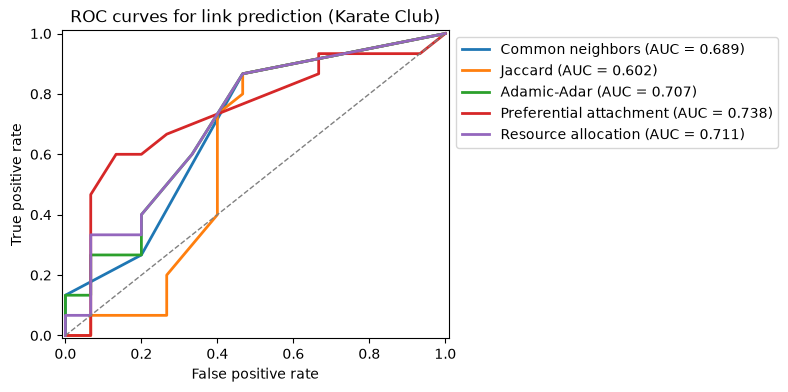

In [35]:
plot_roc_curves(y_karate, score_dict_karate, "ROC curves for link prediction (Karate Club)")

### Your turn! Visualize the top 10 highest-score pairs from each method

For each method, rank all 30 candidate pairs (the 15 hidden edges in `test_karate` and the 15 sampled non-edges in `neg_karate`) by score, and draw the 10 highest-scoring pairs on top of the training graph. Use one color for the pairs that really were hidden edges and another for the ones that weren't.

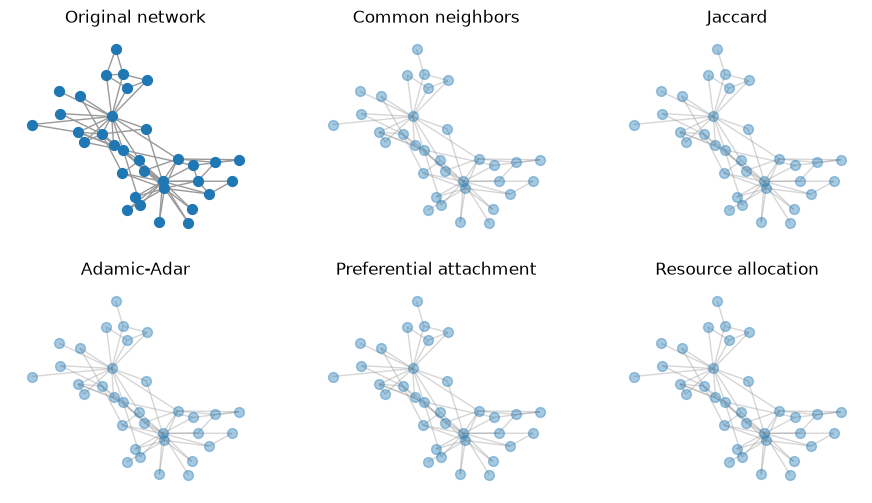

In [36]:
fig, ax = plt.subplots(2,3,figsize=(11,6),dpi=100)

# One fixed layout for all six panels, so each node sits in the same place everywhere
pos_karate = nx.spring_layout(G_karate, seed=SEED)
nx.draw(G_karate, pos_karate, node_size=50, edge_color='.6', ax=ax[(0,0)])
ax[(0,0)].set_title('Original network')

#########################################

nx.draw(G_karate_train, pos_karate, node_size=50, edge_color='.6', ax=ax[(0,1)], alpha=0.4)
# 1. score every pair in test_karate + neg_karate with common_neighbors_score on G_karate_train
# 2. keep the 10 highest-scoring pairs
# 3. draw the ones that are in test_karate in one color, the rest in another, e.g.
#    nx.draw_networkx_edges(nx.Graph(hits), pos_karate, edge_color='mediumseagreen', width=2, ax=ax[(0,1)])
ax[(0,1)].set_title('Common neighbors')


nx.draw(G_karate_train, pos_karate, node_size=50, edge_color='.6', ax=ax[(0,2)], alpha=0.4)
## ...
ax[(0,2)].set_title('Jaccard')


nx.draw(G_karate_train, pos_karate, node_size=50, edge_color='.6', ax=ax[(1,0)], alpha=0.4)
## ...
ax[(1,0)].set_title('Adamic-Adar')


nx.draw(G_karate_train, pos_karate, node_size=50, edge_color='.6', ax=ax[(1,1)], alpha=0.4)
## ...
ax[(1,1)].set_title('Preferential attachment')


nx.draw(G_karate_train, pos_karate, node_size=50, edge_color='.6', ax=ax[(1,2)], alpha=0.4)
## ...
ax[(1,2)].set_title('Resource allocation')

plt.show()

_______
Solution below. Try the exercise first.

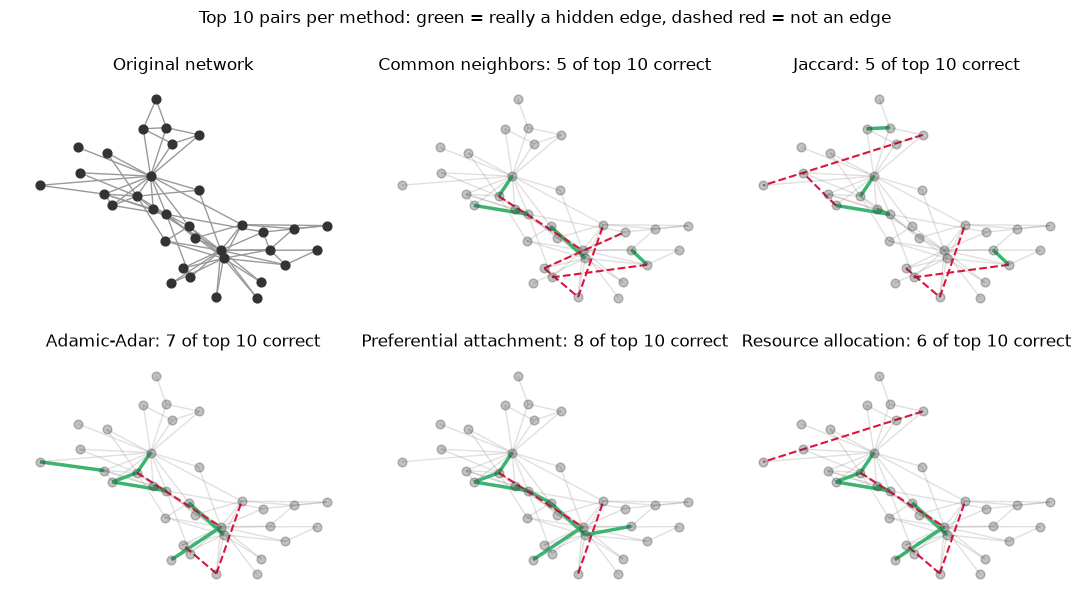

In [37]:
fig, ax = plt.subplots(2,3,figsize=(11,6),dpi=100)

# Same fixed layout as the exercise cell
pos_karate = nx.spring_layout(G_karate, seed=SEED)
nx.draw(G_karate, pos_karate, node_size=40, node_color='.2',
        edge_color='.6', ax=ax[(0,0)])
ax[(0,0)].set_title('Original network')

#############################

num_plot = 10

# All 30 pairs we scored: the hidden edges first, then the sampled non-edges
candidates = test_karate + neg_karate
is_hidden_edge = np.array([1] * len(test_karate) + [0] * len(neg_karate))

subplots = [(0,1),(0,2),(1,0),(1,1),(1,2)]
rng_ties = np.random.default_rng(SEED)   # for breaking ties at random, as in precision_at_k

for a, (name, fn) in zip(subplots, [
    ("Common neighbors", common_neighbors_score),
    ("Jaccard", jaccard_score),
    ("Adamic-Adar", adamic_adar_score),
    ("Preferential attachment", preferential_attachment_score),
    ("Resource allocation", resource_allocation_score),
]):
    scores = np.array([fn(G_karate_train, i, j) for (i, j) in candidates])

    # Rank the candidates by score (ties in random order) and keep the top num_plot
    perm = rng_ties.permutation(len(scores))
    top = perm[np.argsort(-scores[perm], kind="stable")][:num_plot]

    # Split the top pairs into hits (really hidden edges) and misses (non-edges)
    hits = [candidates[t] for t in top if is_hidden_edge[t] == 1]
    misses = [candidates[t] for t in top if is_hidden_edge[t] == 0]

    nx.draw(G_karate_train, pos_karate, node_size=40, node_color='.2',
            edge_color='.6', ax=ax[a], alpha=0.3)
    nx.draw_networkx_edges(nx.Graph(hits), pos_karate, edge_color='mediumseagreen',
                           width=2.5, ax=ax[a])
    nx.draw_networkx_edges(nx.Graph(misses), pos_karate, edge_color='crimson',
                           width=1.5, style='--', ax=ax[a])
    ax[a].set_title(f"{name}: {len(hits)} of top {num_plot} correct")

plt.suptitle('Top 10 pairs per method: green = really a hidden edge, dashed red = not an edge', y=1.0)
plt.tight_layout()
plt.show()

With this split, preferential attachment again has the highest AUC (0.74), and 8 of its top 10 pairs are real hidden edges; the neighborhood scores get 5 to 7 right. Don't read too much into the ordering, though. There are only 15 hidden edges and 15 non-edges, so each hidden edge carries 1/15 of the AUC; one or two of them moving up or down the ranking shifts the AUC by several hundredths. Change `SEED` and rerun: over seeds 0 to 19, preferential attachment comes out on top in 10 of the 20 splits and one of the neighborhood scores in the rest. (A random ranking would get about 5 of 10, since half of the 30 candidates are hidden edges.) What does hold up is that common neighbors, Adamic-Adar, resource allocation and preferential attachment beat guessing on average (mean AUC about 0.69 to 0.73 over seeds 0 to 199). Jaccard is weaker: about 0.62 on average, and below 0.5 in one split in ten. None of that is true of the disassortative SBM below.

-------

## When local heuristics fail: a disassortative SBM

Neighborhood-based scores implicitly assume a kind of **homophily**: nodes with similar neighbors tend to connect. This is often reasonable (social networks, collaboration networks) but not universal.

To see a failure case, consider a simple stochastic block model (SBM) with two groups of equal size where edges are more likely between groups than within groups. In this disassortative setting, many new edges connect structurally dissimilar nodes, and local similarity measures can perform poorly.

In [38]:
# Disassortative SBM
sizes = [40, 40]
# p[r][s] is the probability of an edge between a node in group r and a node in group s:
# 0.02 inside a group, 0.15 across groups
p = [[0.02, 0.15],
     [0.15, 0.02]]

G_sbm = nx.stochastic_block_model(sizes, p, seed=SEED)

G_sbm_train, test_sbm, neg_sbm = train_test_split_graph(
    G_sbm, test_frac=0.2, seed=SEED, ensure_connected=True
)

print("SBM (disassortative)")
print("  Nodes:", G_sbm.number_of_nodes())
print("  Edges:", G_sbm.number_of_edges())
print("  Test positives:", len(test_sbm))
print("  Test negatives:", len(neg_sbm))


SBM (disassortative)
  Nodes: 80
  Edges: 284
  Test positives: 56
  Test negatives: 56


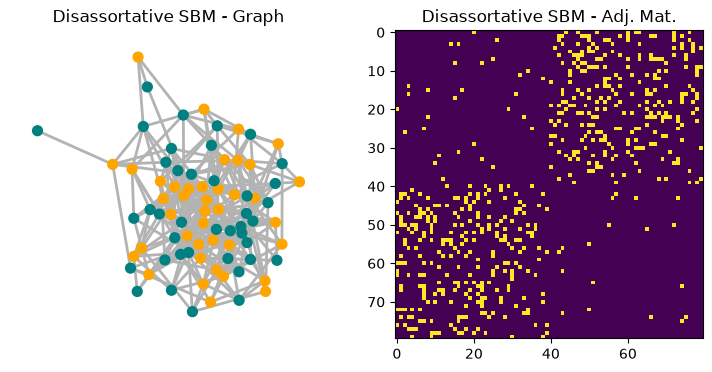

In [39]:
fig, ax = plt.subplots(1,2,figsize=(9,4),dpi=100)

# Left: the graph, colored by group. Right: the adjacency matrix (nodes 0-39 are one group, 40-79 the other)
nx.draw(G_sbm,pos=nx.spring_layout(G_sbm, seed=SEED),node_size=50,width=2,edge_color='.7',
        node_color=['orange']*40+['teal']*40,ax=ax[0])
ax[1].imshow(nx.to_numpy_array(G_sbm))

ax[0].set_title('Disassortative SBM - Graph')
ax[1].set_title('Disassortative SBM - Adj. Mat.')

plt.show()

In [40]:
# Same five scores, now on the disassortative SBM
results = {}
for name, fn in [
    ("Common neighbors", common_neighbors_score),
    ("Jaccard", jaccard_score),
    ("Adamic-Adar", adamic_adar_score),
    ("Preferential attachment", preferential_attachment_score),
    ("Resource allocation", resource_allocation_score),
]:
    y, s, auc = evaluate_score_function(G_sbm_train, test_sbm, neg_sbm, fn, verbose=False)
    results[name] = (y, s, auc)

for name, (y, s, auc) in results.items():
    print(f"{name:23s}: SBM ROC-AUC = {auc:.3f}")

Common neighbors       : SBM ROC-AUC = 0.371
Jaccard                : SBM ROC-AUC = 0.370
Adamic-Adar            : SBM ROC-AUC = 0.363
Preferential attachment: SBM ROC-AUC = 0.538
Resource allocation    : SBM ROC-AUC = 0.363


On this disassortative network, the four neighborhood scores do *worse* than random (an AUC below 0.5), and preferential attachment hovers around 0.5. That is not bad luck: change `SEED` and rerun, and the neighborhood scores stay below 0.5 about nine times in ten (over seeds 0 to 99, the common-neighbors AUC averages about 0.43). Two nodes in the same group share lots of neighbors (they both link to the other group) but rarely link to each other. Two nodes in different groups link often but share few neighbors, because a common neighbor of a cross-group pair needs a within-group edge. So a high neighborhood score points at the wrong pairs. Flip the sign and you would get an AUC above 0.5: the information is in the scores, but the assumption behind them is backwards. A model that learns the group structure gets this right; Appendix H of Class 9 does link prediction with an SBM fit in `graph-tool`.

Link prediction methods are not universally reliable. Each one encodes an assumption about how edges form.

### Homophily vs. heterophily

- Homophily suggests that similar nodes are more likely to connect, whereas heterophily implies connections between dissimilar nodes.
- Homophily-based methods (like common neighbors or Jaccard) work well for networks where similar nodes are connected, but they struggle in heterophilic networks.
- For networks formed through heterophily (e.g., connections between dissimilar or complementary nodes), we might need different predictors or additional features (such as node attributes) to account for these dissimilarities.

Some papers that take such features into account: [Zheng et al., 2022](https://arxiv.org/abs/2202.07082), [Zhu et al., 2021](https://arxiv.org/abs/2009.13566), and [Kovács et al., 2019](https://www.nature.com/articles/s41467-019-09177-y).

Kovács et al. (2019) ran into exactly this in protein interaction networks. Two proteins that share many partners are not more likely to interact, because similar proteins tend to bind the same targets rather than each other. So common neighbors fails there for the same reason as in our SBM. They score a pair by the number of paths of length three between them instead (degree-normalized; they call it L3).

![](images/proteins.png)

### Final point: Link prediction and recommendation systems

Many recommender systems can be represented as a **bipartite graph** between a set of users $U$ and a set of items $I$. An edge $(u, i)$ indicates that user $u \in U$ has interacted with item $i \in I$ (watched a movie, purchased a product, clicked a link, followed an account, and so on). The goal of recommendation is then:

> For each user $u$, identify a small set of items $i$ such that the missing edges $(u, i)$ are most likely to appear in the future.

This is exactly a link prediction problem on a bipartite graph. The candidate set consists of all non-edges $(u, i)$ that are not currently observed; a recommendation algorithm assigns a score $s(u, i)$ to each candidate pair and returns the top-$k$ items per user. The evaluation metrics are essentially the same as in this chapter:

* ROC-AUC and related ranking metrics (such as average precision) measure how well the algorithm separates edges that will appear from those that will not.
* Precision@$k$ measures the fraction of recommended items that correspond to true future interactions.

What changes in practice is the scale and the data. Real recommendation systems have to cope with:

* extremely large candidate sets and severe class imbalance,
* side information about users and items (attributes, content, context),
* strong temporal and causal constraints (for example, avoiding using future interactions when training).

______________

Everything in this notebook was a hand-built score. Much of the recent work learns the score from data instead. Random-walk embeddings such as DeepWalk and node2vec learn a vector for each node by treating short random walks like sentences (Perozzi et al., 2014; Grover and Leskovec, 2016). Graph neural networks such as GCNs and GATs learn how to combine information from a node's neighbors (Kipf and Welling, 2017; Veličković et al., 2018; Hamilton et al., 2017). We'll meet these ideas in the machine-learning classes. There is also work on stacking many predictors into one, which comes close to the best achievable performance across hundreds of real networks (Ghasemian et al., 2020), and on methods built for heterogeneous or heterophilous graphs (Dong et al., 2017; Wang et al., 2019; Fu et al., 2020; Zheng et al., 2022; Zhu et al., 2021). The references below are a good place to start.

__________
## Next time...
Visualization — Python! `class_11_visualization.ipynb`
_______

## References and further resources:

1. Class Webpages
    - Jupyter Book: https://computational-methods-network-science.github.io/nets7052_fa26/README.html
    - Github: https://github.com/computational-methods-network-science/nets7052_fa26/
    - Syllabus and course details: https://brennanklein.com/nets7052-fall26
2. Adamic, L. A., & Adar, E. (2003). Friends and neighbors on the web. *Social Networks*, 25(3), 211–230. https://doi.org/10.1016/S0378-8733(03)00009-1
3. Al Hasan, M., Chaoji, V., Salem, S., & Zaki, M. (2006). Link prediction using supervised learning. In *SDM'06 Workshop on Link Analysis, Counter-terrorism and Security*.
4. Albert, R., & Barabási, A.-L. (2002). Statistical mechanics of complex networks. *Reviews of Modern Physics*, 74(1), 47–97. https://doi.org/10.1103/RevModPhys.74.47
5. Barabási, A.-L., Jeong, H., Néda, Z., Ravasz, E., Schubert, A., & Vicsek, T. (2002). Evolution of the social network of scientific collaborations. *Physica A*, 311(3–4), 590–614. https://doi.org/10.1016/S0378-4371(02)00736-7
6. Clauset, A., Moore, C., & Newman, M. E. J. (2008). Hierarchical structure and the prediction of missing links in networks. *Nature*, 453(7191), 98–101. https://doi.org/10.1038/nature06830
7. Fawcett, T. (2006). An introduction to ROC analysis. *Pattern Recognition Letters*, 27(8), 861–874. https://doi.org/10.1016/j.patrec.2005.10.010
8. Katz, L. (1953). A new status index derived from sociometric analysis. *Psychometrika*, 18(1), 39–43. https://doi.org/10.1007/BF02289026
9. Kovács, I. A., Luck, K., Spirohn, K., Wang, Y., Pollis, C., Schlabach, S., Bian, W., Kim, D.-K., Kishore, N., Hao, T., Calderwood, M. A., Vidal, M., & Barabási, A.-L. (2019). Network-based prediction of protein interactions. *Nature Communications*, 10, 1240. https://doi.org/10.1038/s41467-019-09177-y
10. Liben-Nowell, D., & Kleinberg, J. (2007). The link-prediction problem for social networks. *Journal of the American Society for Information Science and Technology*, 58(7), 1019–1031. https://doi.org/10.1002/asi.20591
11. Lü, L., & Zhou, T. (2011). Link prediction in complex networks: A survey. *Physica A: Statistical Mechanics and its Applications*, 390(6), 1150–1170. https://doi.org/10.1016/j.physa.2010.11.027
12. Newman, M. E. J. (2001). Clustering and preferential attachment in growing networks. *Physical Review E*, 64(2), 025102. https://doi.org/10.1103/PhysRevE.64.025102
13. Newman, M. E. J. (2018). *Networks* (2nd ed.). Oxford University Press.
14. Zhou, T., Lü, L., & Zhang, Y.-C. (2009). Predicting missing links via local information. *The European Physical Journal B*, 71(4), 623–630. https://doi.org/10.1140/epjb/e2009-00335-8
15. Ghasemian, A., Hosseinmardi, H., Galstyan, A., Airoldi, E. M., & Clauset, A. (2020). Stacking models for nearly optimal link prediction in complex networks. *Proceedings of the National Academy of Sciences of the United States of America*, 117(38), 23393–23400. https://doi.org/10.1073/pnas.1914950117
16. Perozzi, B., Al-Rfou, R., & Skiena, S. (2014). DeepWalk: Online learning of social representations. In *Proceedings of the 20th ACM SIGKDD International Conference on Knowledge Discovery and Data Mining (KDD ’14)* (pp. 701–710). https://doi.org/10.1145/2623330.2623732
17. Grover, A., & Leskovec, J. (2016). node2vec: Scalable feature learning for networks. In *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining (KDD ’16)* (pp. 855–864). https://doi.org/10.1145/2939672.2939754
18. Veličković, P., Cucurull, G., Casanova, A., Romero, A., Liò, P., & Bengio, Y. (2018). Graph attention networks. In *International Conference on Learning Representations (ICLR 2018)*. arXiv:1710.10903. https://arxiv.org/abs/1710.10903
19. Kipf, T. N., & Welling, M. (2017). Semi-supervised classification with graph convolutional networks. In *International Conference on Learning Representations (ICLR 2017)*. arXiv:1609.02907. https://arxiv.org/abs/1609.02907
20. Hamilton, W. L., Ying, R., & Leskovec, J. (2017). Inductive representation learning on large graphs. In *Advances in Neural Information Processing Systems (NeurIPS 2017)* (pp. 1025–1035). arXiv:1706.02216. https://arxiv.org/abs/1706.02216
21. Dong, Y., Chawla, N. V., & Swami, A. (2017). metapath2vec: Scalable representation learning for heterogeneous networks. In *Proceedings of the 23rd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining (KDD ’17)* (pp. 135–144). https://doi.org/10.1145/3097983.3098036
22. Wang, X., Ji, H., Shi, C., Wang, B., Ye, Y., Cui, P., & Yu, P. S. (2019). Heterogeneous graph attention network. In *Proceedings of the World Wide Web Conference (WWW 2019)* (pp. 2022–2032). https://doi.org/10.1145/3308558.3313562
23. Fu, X., Zhang, J., Meng, Z., & King, I. (2020). MAGNN: Metapath aggregated graph neural network for heterogeneous graph embedding. In *Proceedings of the Web Conference 2020 (WWW ’20)* (pp. 2331–2341). https://doi.org/10.1145/3366423.3380297
24. Zheng, X., Wang, Y., Liu, Y., Li, M., Zhang, M., Jin, D., Yu, P. S., & Pan, S. (2022). Graph neural networks for graphs with heterophily: A survey. *arXiv preprint* arXiv:2202.07082. https://arxiv.org/abs/2202.07082
25. Zhu, J., Rossi, R. A., Rao, A., Mai, T., Lipka, N., Ahmed, N. K., & Koutra, D. (2021). Graph neural networks with heterophily. *Proceedings of the AAAI Conference on Artificial Intelligence*, 35(12), 11168–11176. https://doi.org/10.1609/aaai.v35i12.17332